## 300m rule: stats & vizualization

In [113]:
CITY = "bologna"

In [114]:
import math
import os

import geopandas as gpd
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import osmnx as ox
import pandas as pd
from shapely.strtree import STRtree

os.chdir("/Users/terezasaskova/Library/Mobile Documents/com~apple~CloudDocs/3-30-300-index")

from config import CRS_METRIC, CRS_WGS, get_city_cfg, get_output_paths

cfg   = get_city_cfg(CITY)
src   = cfg["data_sources"]
paths = get_output_paths(CITY)

# figure output dir — create if needed
FIG_DIR = paths["fig_dir"]
os.makedirs(FIG_DIR, exist_ok=True)

print(f"City   : {CITY}")
print(f"Figures: {FIG_DIR}")

City   : bologna
Figures: /Users/terezasaskova/Library/Mobile Documents/com~apple~CloudDocs/3-30-300-index/fig/bologna


In [115]:
TEAL  = "#1D9E75"
BLUE  = "#378ADD"
CORAL = "#F0997B"
LGRAY = "#D3D1C7"
AMBER = "#EF9F27"
TEXT  = "#2C2C2A"
SGRAY = "#888780"

plt.rcParams.update({
    "font.family":        "sans-serif",
    "font.size":          11,
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "axes.linewidth":     0.6,
    "xtick.major.size":   3,
    "ytick.major.size":   3,
    "figure.dpi":         150,
    "savefig.bbox":       "tight",
    "savefig.dpi":        150,
})

In [9]:
buildings_routed = gpd.read_file(paths["gpkg"], layer="buildings")
parks            = gpd.read_file(paths["gpkg"], layer="parks")
results          = pd.read_csv(paths["csv"])

print(f"{len(results):,} address records loaded")
print(f"{len(parks):,} parks loaded")

77,630 address records loaded
1,158 parks loaded


In [21]:
print(parks.head())

     area_ha source   layer_type  name  park_id  \
0   3.139692   DBSN  pe_unis_all  None        3   
1   7.147847   DBSN  pe_unis_all  None       12   
2   0.111772   DBSN  pe_unis_all  None       13   
3  30.834538   DBSN  pe_unis_all  None       19   
4   3.033564   DBSN  pe_unis_all  None       20   

                                            geometry  
0  MULTIPOLYGON (((684850.269 4923642.531, 684850...  
1  MULTIPOLYGON (((684801.936 4924278.707, 684832...  
2  MULTIPOLYGON (((684346.959 4924313.734, 684329...  
3  MULTIPOLYGON (((683368.784 4924068.699, 683405...  
4  MULTIPOLYGON (((682688.422 4924856.478, 682688...  


## 1. Greenery

In [ ]:
park_area = (
    parks[["park_id", "geometry"]]
    .copy()
    .to_crs(CRS_METRIC)
    .assign(area_ha=lambda df: df.geometry.area / 10_000)
    [["park_id", "area_ha"]]
)

print(f"parks unique park_id: {parks['park_id'].nunique()} / {len(parks)}")

results = results.merge(
    park_area.rename(columns={"park_id": "nearest_park_id"}),
    on="nearest_park_id",
    how="left",
)

# Derive compliance columns used downstream
results["compliant_0ha"]   = results["within_300m"]
results["compliant_0.5ha"] = results["within_300m"] & (results["area_ha"] >= 0.5)
results["compliant_1.0ha"] = results["within_300m"] & (results["area_ha"] >= 1.0)

print(f"area_ha range: {results['area_ha'].min():.2f} – {results['area_ha'].max():.2f} ha")

parks unique park_id: 1158 / 1158
results rows before merge: 77630
results rows after merge: 77630
area_ha range: 0.00 – 45.60 ha


## 2. 300 m compliance - statistics

In [147]:
total  = len(results)
avg = results['within_300m'].mean()
within  = results['within_300m'].sum()
no_park = results['nearest_park_id'].isna().sum()
routed = results['nearest_park_id'].notna().sum()
outside = routed - within        

print('300m PARK ACCESS INDICATOR — BOLOGNA')
print(f'STREET NUMBERS:')
print(f'Total civici:                  {total:>8,}')
print(f'Within 300m walk of park:      {within:>8,}  ({within/total*100:.1f}%)')
print(f'Outside 300m (park too far):   {outside:>8,}  ({outside/total*100:.1f}%)')
print(f'No park reachable (NaN):       {no_park:>8,}  ({no_park/total*100:.1f}%)')

print(f'\nWALK DISTANCE (routed buildings only):')
reachable = results[results['nearest_park_id'].notna()]
print(f'Median walk distance:          {results["walk_dist_m"].median():>8.0f} m')
print(f'Mean walk distance:            {results["walk_dist_m"].mean():>8.0f} m')
print(f'Max walk distance:             {results["walk_dist_m"].max():>8.0f} m')

print(f'\nPARKS REACHED:')
print(f'Unique parks accessed:         {results["nearest_park_id"].nunique():>8,}')


300m PARK ACCESS INDICATOR — BOLOGNA
STREET NUMBERS:
Total civici:                    77,630
Within 300m walk of park:        59,266  (76.3%)
Outside 300m (park too far):      2,133  (2.7%)
No park reachable (NaN):         16,231  (20.9%)

WALK DISTANCE (routed buildings only):
Median walk distance:               130 m
Mean walk distance:                 141 m
Max walk distance:                 3184 m

PARKS REACHED:
Unique parks accessed:            1,158


## 3. Neighbourhoods

In [117]:
HAS_NEIGHBOURHOODS = "neighbourhood" in results.columns and results["neighbourhood"].notna().any()


## VIZUALIZATION

In [118]:
total   = len(results)
avg     = results["within_300m"].mean() * 100  
within  = results["within_300m"].sum()
no_park = results["nearest_park_id"].isna().sum()
routed  = results["nearest_park_id"].notna().sum()
outside = routed - within

## fig01. neighbourhood compliance with 300m rule

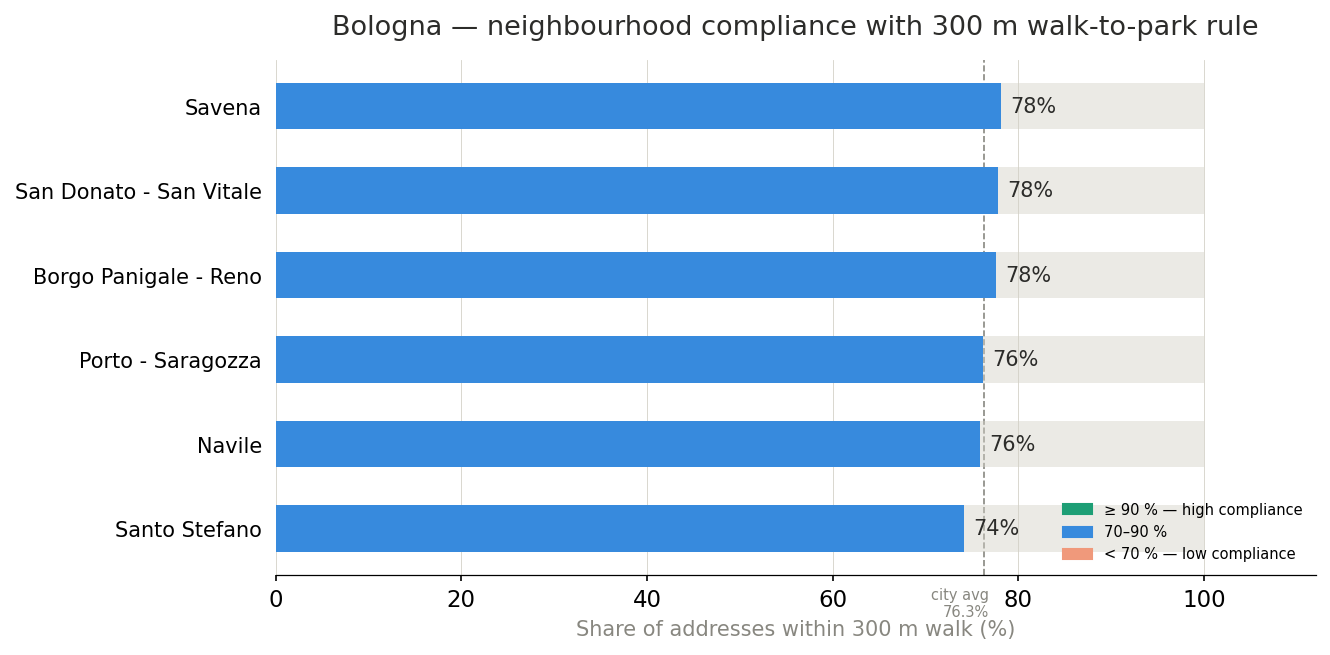

In [119]:
if not HAS_NEIGHBOURHOODS:
    print("Skipping fig01 — no neighbourhood data")
else:
    nb = (
        results.groupby("neighbourhood")["within_300m"]
        .agg(total="count", within="sum")
        .assign(pct=lambda x: x["within"] / x["total"] * 100)
        .sort_values("pct", ascending=True)
        .reset_index()
    )

    fig, ax = plt.subplots(figsize=(9, max(4.5, len(nb) * 0.55)))
    y     = np.arange(len(nb))
    BAR_H = 0.55
    colors = [TEAL if p >= 90 else BLUE if p >= 70 else CORAL for p in nb.pct]

    ax.barh(y, nb.pct,         height=BAR_H, color=colors, zorder=2)
    ax.barh(y, 100 - nb.pct,   height=BAR_H, left=nb.pct, color=LGRAY, alpha=0.45, zorder=2)

    for i, row in nb.iterrows():
        ax.text(row.pct + 1, i, f"{row.pct:.0f}%", va="center", fontsize=10, color=TEXT)
        if row.pct >= 99.5:
            ax.text(row.pct - 2, i, "✓", va="center", ha="right",
                    fontsize=11, color="white", fontweight="bold")

    ax.set_yticks(y)
    ax.set_yticklabels(nb.neighbourhood, fontsize=10)
    ax.set_xlabel("Share of addresses within 300 m walk (%)", fontsize=10, color=SGRAY)
    ax.set_xlim(0, 112)
    ax.set_title(f"{CITY.title()} — neighbourhood compliance with 300 m walk-to-park rule",
                 fontsize=13, fontweight="500", pad=12, color=TEXT)
    ax.axvline(avg, color=SGRAY, linewidth=0.8, linestyle="--", zorder=1)
    ax.text(avg + 0.5, -0.7, f"city avg\n{avg:.1f}%", fontsize=7, color=SGRAY, va="top", ha="right")
    ax.grid(axis="x", linewidth=0.4, color=LGRAY, zorder=0)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(left=False)
    ax.legend(
        handles=[
            mpatches.Patch(color=TEAL,  label="≥ 90 % — high compliance"),
            mpatches.Patch(color=BLUE,  label="70–90 %"),
            mpatches.Patch(color=CORAL, label="< 70 % — low compliance"),
        ],
        loc="lower right", fontsize=7, frameon=False,
    )
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/fig01_neighborhood_walkability_compliance.png", dpi=150)
    plt.show()

In [120]:
if HAS_NEIGHBOURHOODS:
    nb_detail = (
        results.groupby("neighbourhood")
        .agg(
            total     =("within_300m",   "count"),
            compliant =("compliant_0ha",  "sum"),
            comp_05ha =("compliant_0.5ha","sum"),
        )
        .assign(
            compliance_pct=lambda x: x.compliant  / x.total * 100,
            base_pct      =lambda x: x.compliant  / x.total * 100,
            pct_05ha      =lambda x: x.comp_05ha  / x.total * 100,
        )
        .sort_values("compliance_pct", ascending=False)
    )

In [121]:
# Fetch admin boundaries for neighbourhood map panels
# admin_level 10 = quartieri for Bologna; adjust tag value if needed for other cities.
if HAS_NEIGHBOURHOODS:
    city_gdf  = ox.geocode_to_gdf(cfg["query"])
    quartieri = ox.features_from_place(cfg["query"], tags={"admin_level": "10"})
    quartieri = quartieri[
        quartieri.geometry.geom_type.isin(["Polygon", "MultiPolygon"])
    ][["name", "geometry"]].reset_index(drop=True)
    print(f"{len(quartieri)} neighbourhood polygons fetched")

7 neighbourhood polygons fetched


## fig02. park access by neighbourhood

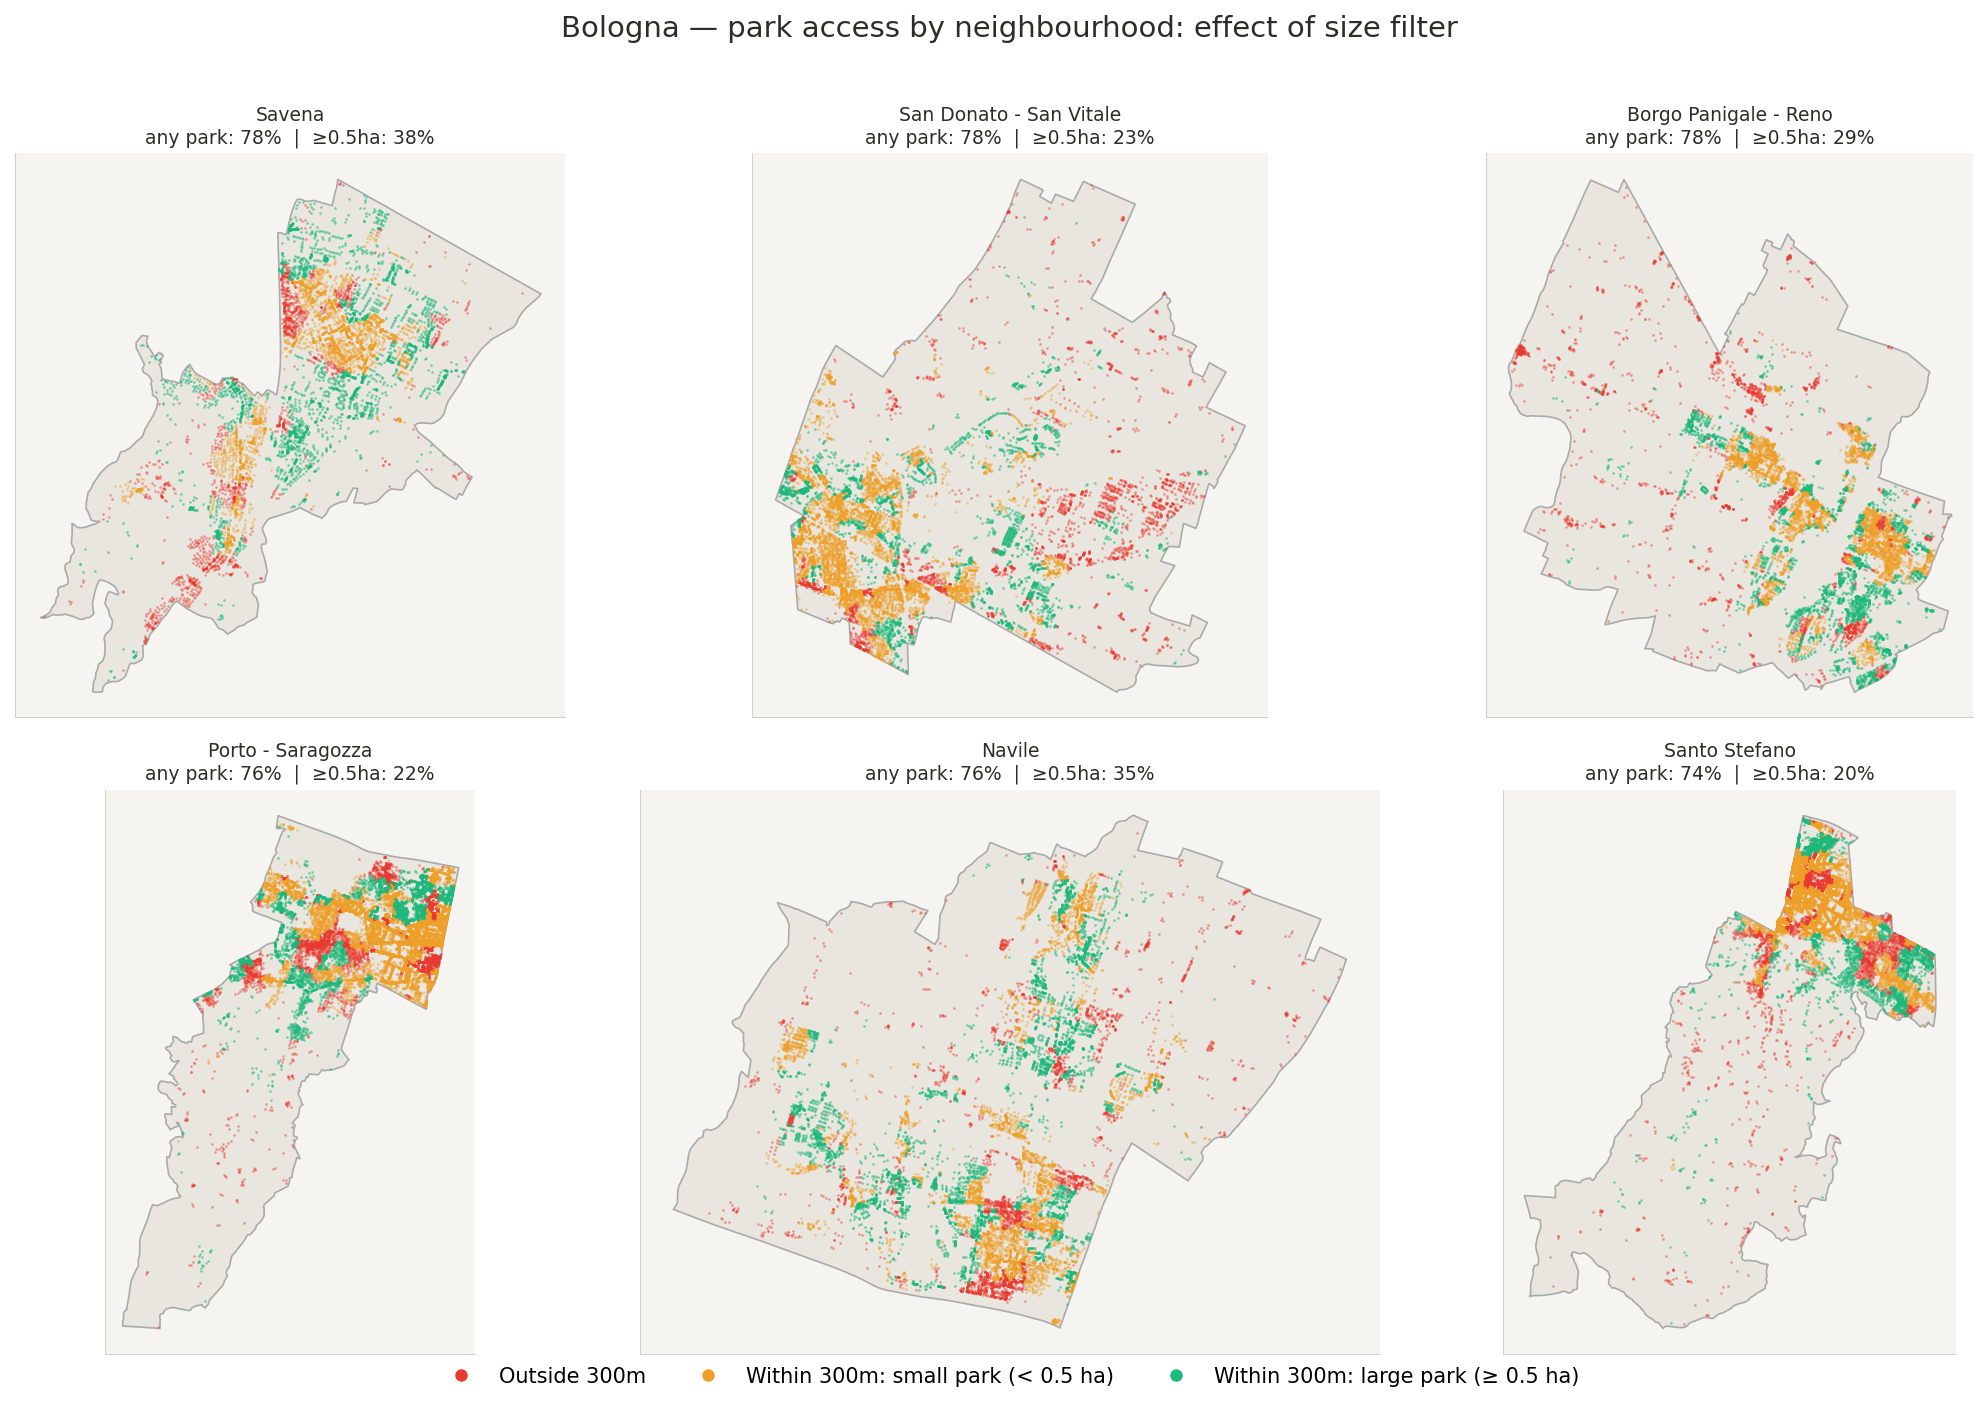

In [123]:
if not HAS_NEIGHBOURHOODS:
    print("Skipping fig02 — no neighbourhood data")
else:
    from matplotlib.lines import Line2D

    neighbourhoods = nb_detail.index.tolist()
    n_cols = 3
    n_rows = math.ceil(len(neighbourhoods) / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 4.5))
    axes = axes.flatten()

    for i, nb in enumerate(neighbourhoods):
        ax    = axes[i]
        nb_df = results[results["neighbourhood"] == nb]

        inside_large = nb_df[nb_df["within_300m"] & (nb_df["area_ha"] >= 0.5)]
        inside_small = nb_df[nb_df["within_300m"] & (nb_df["area_ha"] <  0.5)]
        outside_df   = nb_df[~nb_df["within_300m"]]

        nb_geom = quartieri[quartieri["name"].str.contains(
            nb.split(" - ")[0], case=False, na=False
        )]
        if not nb_geom.empty:
            nb_geom.plot(ax=ax, facecolor="#E8E6DF", edgecolor="#AAAAAA",
                         linewidth=0.8, zorder=1)

        ax.set_facecolor("#F5F4F0")
        ax.scatter(outside_df["longitude"],    outside_df["latitude"],
                   s=1.5, color="#E83A2F", alpha=0.5, linewidths=0, zorder=2, rasterized=True)
        ax.scatter(inside_small["longitude"],  inside_small["latitude"],
                   s=1.5, color=AMBER,     alpha=0.5, linewidths=0, zorder=3, rasterized=True)
        ax.scatter(inside_large["longitude"],  inside_large["latitude"],
                   s=1.5, color="#1DB87A", alpha=0.6, linewidths=0, zorder=4, rasterized=True)

        row = nb_detail.loc[nb]
        ax.set_title(
            f"{nb}\nany park: {row.base_pct:.0f}%  |  ≥0.5ha: {row.pct_05ha:.0f}%",
            fontsize=9, color=TEXT, pad=5,
        )
        ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_edgecolor(LGRAY); spine.set_linewidth(0.5)

    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)

    fig.legend(
        handles=[
            Line2D([0],[0], marker='o', color='w', markerfacecolor="#E83A2F", markersize=7, label="Outside 300m"),
            Line2D([0],[0], marker='o', color='w', markerfacecolor=AMBER,     markersize=7, label="Within 300m: small park (< 0.5 ha)"),
            Line2D([0],[0], marker='o', color='w', markerfacecolor="#1DB87A", markersize=7, label="Within 300m: large park (≥ 0.5 ha)"),
        ],
        loc="lower center", ncol=3, fontsize=10, frameon=False, bbox_to_anchor=(0.5, -0.02),
    )
    fig.suptitle(f"{CITY.title()} — park access by neighbourhood: effect of size filter",
                 fontsize=14, fontweight="500", color=TEXT, y=1.01)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/fig02_walkability_compliance_by_neighborhood_map.png",
                bbox_inches="tight", dpi=180)
    plt.show()

## 

In [ ]:
# First, compute the base metrics
within_300m = results["within_300m"]              
meets_05ha = results["compliant_0.5ha"]  # Has park within 300m AND ≥ 0.5ha
meets_10ha = results["compliant_1.0ha"]  # Has park within 300m AND ≥ 1.0ha

# For 0.5ha threshold
lost_distance_05 = within_300m & ~meets_05ha  # Within 300m but too small
lost_size_05 = (~within_300m) & results["compliant_0.5ha"]  # Beyond 300m but would qualify

# For 1.0ha threshold  
lost_distance_10 = within_300m & ~meets_10ha
lost_size_10 = (~within_300m) & results["compliant_0.5ha"]

# Build the dataframe
size_df = pd.DataFrame([
    {
        "threshold": 0,
        "c_pct":  within_300m.mean() * 100,  # All within 300m
        "l_pct":  0,
        "n_pct":  (~within_300m).mean() * 100,  # None within 300m
        "parks":  results["nearest_park_id"].nunique(),
    },
    {
        "threshold": 0.5,
        "c_pct":  meets_05ha.mean() * 100,
        "l_pct":  lost_distance_05.mean() * 100,  # Within 300m, too small
        "n_pct":  (~within_300m).mean() * 100,  # No park within 300m
        "parks":  results[results["area_ha"] >= 0.5]["nearest_park_id"].nunique(),
    },
    {
        "threshold": 1.0,
        "c_pct":  meets_10ha.mean() * 100,
        "l_pct":  lost_distance_10.mean() * 100,  # Within 300m, too small
        "n_pct":  (~within_300m).mean() * 100,  # No park within 300m
        "parks":  results[results["area_ha"] >= 1.0]["nearest_park_id"].nunique(),
    },
])



## fig03. 300m by parksize
- sicne according to WHO park should be at least 0,5 ha 

Three address groups at each threshold:
- compliant  — within 300m of a park that meets the size requirement
- lost       — within 300m but their nearest park is smaller than threshold
- never      — never within 300m regardless of size (no park reachable)

"lost" is computed as: was within 300m at baseline, but the matched park is smaller than t ha.  It accumulates as threshold rises.

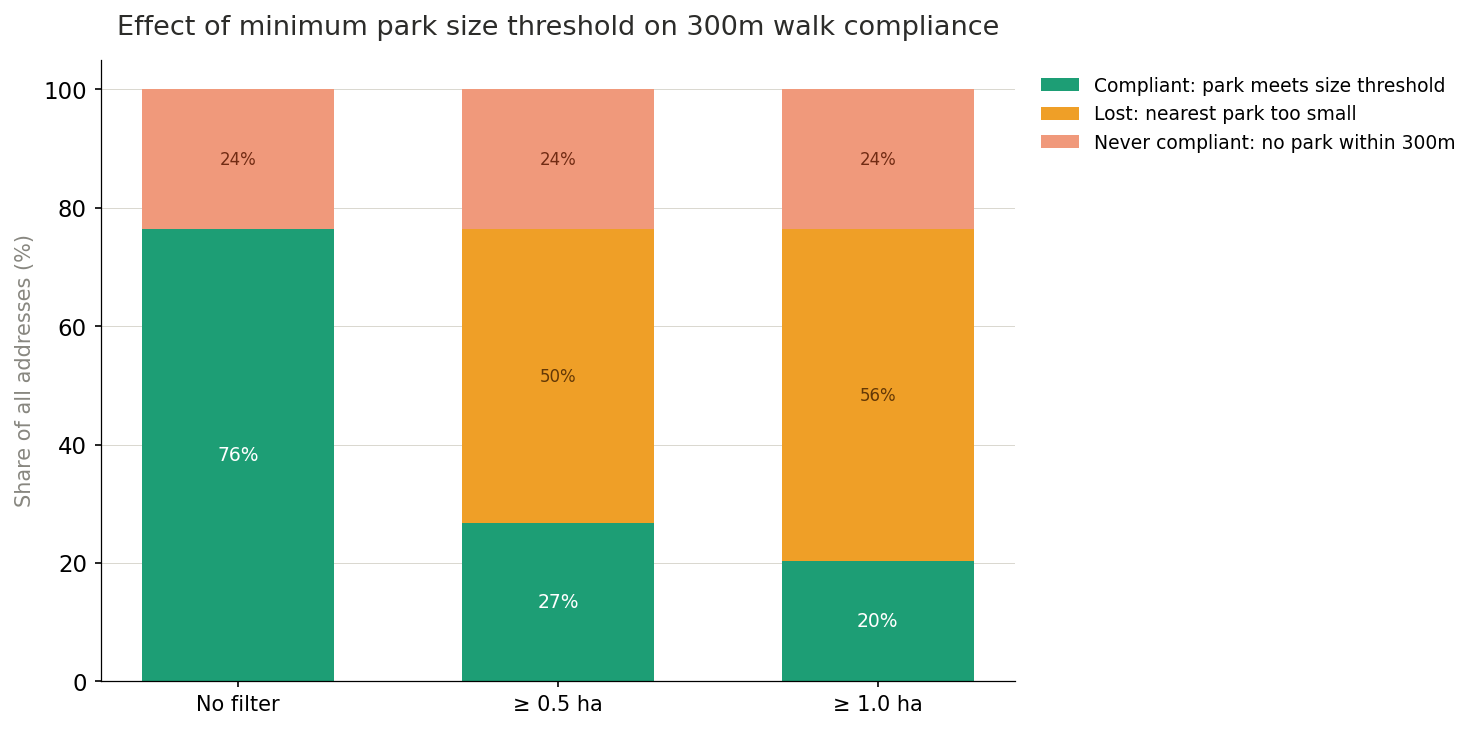

In [126]:
x       = size_df.index.to_numpy()
width   = 0.6
xlabels = ["No filter", "≥ 0.5 ha", "≥ 1.0 ha"]
#Stacked compliance bars
fig, ax_top = plt.subplots(figsize=(10, 5))

b1 = ax_top.bar(x, size_df.c_pct, width, color=TEAL,  label="Compliant: park meets size threshold", zorder=2)
b2 = ax_top.bar(x, size_df.l_pct, width, bottom=size_df.c_pct, color=AMBER, label="Lost: nearest park too small", zorder=2)
b3 = ax_top.bar(x, size_df.n_pct, width, bottom=size_df.c_pct + size_df.l_pct, color=CORAL, label="Never compliant: no park within 300m", zorder=2)

for i, row in size_df.iterrows():
    if row.c_pct > 5:
        ax_top.text(i, row.c_pct / 2, f"{row.c_pct:.0f}%",
            ha="center", va="center", fontsize=9, color="white", fontweight="500")
    if row.l_pct > 3:
        ax_top.text(i, row.c_pct + row.l_pct / 2, f"{row.l_pct:.0f}%",
            ha="center", va="center", fontsize=8, color="#633806")
    if row.n_pct > 3:
        ax_top.text(i, row.c_pct + row.l_pct + row.n_pct / 2, f"{row.n_pct:.0f}%",
            ha="center", va="center", fontsize=8, color="#712B13")
ax_top.set_xticks(x)
ax_top.set_xticklabels(xlabels, fontsize=10)
ax_top.set_ylabel("Share of all addresses (%)", fontsize=10, color=SGRAY)
ax_top.set_ylim(0, 105)
ax_top.set_title("Effect of minimum park size threshold on 300m walk compliance",
    fontsize=13, fontweight="500", pad=12, color=TEXT)
ax_top.grid(axis="y", linewidth=0.4, color=LGRAY, zorder=0)
ax_top.legend(fontsize=9, frameon=False, loc="upper left",
    bbox_to_anchor=(1.01, 1.0))

plt.tight_layout()
plt.savefig("fig/fig03_300m_by_parksize.png", bbox_inches="tight", dpi=150)
plt.show()

## fig04. number of parks surviving 0.5 and 1 ha threshold

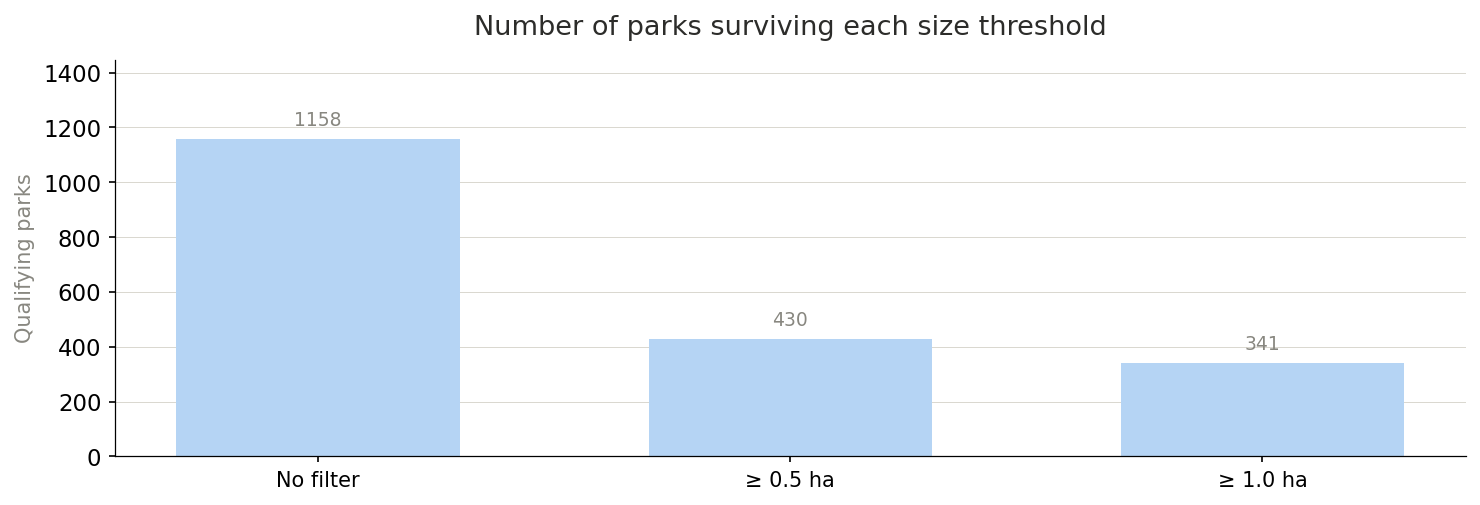

In [127]:
fig, ax_bot = plt.subplots(figsize=(10, 3.5))

ax_bot.bar(x, size_df.parks, width, color="#B5D4F4", zorder=2)
for i, row in size_df.iterrows():
    ax_bot.text(i, row.parks + size_df.parks.max() * 0.03,
        str(int(row.parks)), ha="center", va="bottom", fontsize=9, color=SGRAY)

ax_bot.set_xticks(x)
ax_bot.set_xticklabels(xlabels, fontsize=10)
ax_bot.set_ylabel("Qualifying parks", fontsize=10, color=SGRAY)
ax_bot.set_title("Number of parks surviving each size threshold",
    fontsize=13, fontweight="500", color=TEXT, pad=12)
ax_bot.set_ylim(0, size_df.parks.max() * 1.25)
ax_bot.grid(axis="y", linewidth=0.4, color=LGRAY, zorder=0)

plt.tight_layout()
plt.savefig("fig/fig04_walkability_compliance_by_park_size.png", bbox_inches="tight", dpi=150)
plt.show()

## fig05. euclidean distance vs. walking distance

In [128]:
# Load parks (already have this)
parks_metric = parks.to_crs(CRS_METRIC)
park_tree = STRtree(parks_metric.geometry.values)

# Build matched with civico coords in metric
matched = results[results["entrance_lat"].notna()].copy()

civico_metric = gpd.GeoDataFrame(
    matched,
    geometry=gpd.points_from_xy(matched["longitude"], matched["latitude"]),
    crs=CRS_WGS
).to_crs(CRS_METRIC)

# For each civico, distance to boundary of its nearest_park_id
park_id_to_idx = {pid: i for i, pid in enumerate(parks_metric["park_id"])}

def dist_to_park_boundary(row_idx, park_id):
    if pd.isna(park_id):
        return np.nan
    pidx = park_id_to_idx.get(park_id)
    if pidx is None:
        return np.nan
    return civico_metric.geometry.iloc[row_idx].distance(
        parks_metric.geometry.iloc[pidx].boundary
    )

matched = matched.reset_index(drop=True)
matched["euclid_dist_m"] = [
    dist_to_park_boundary(i, row["nearest_park_id"])
    for i, row in matched.iterrows()
]

In [129]:
w = 0.35

dist_thresholds = [100, 200, 300] 

# Calculate walk_pct_real and euclid_pct_real for EACH threshold
walk_pct_real = []
euclid_pct_real = []
x = []

for threshold in dist_thresholds:
    walk_pct   = (matched["walk_dist_m"]   <= threshold).sum() / total * 100
    euclid_pct = (matched["euclid_dist_m"] <= threshold).sum()/ total  * 100
    walk_pct_real.append(walk_pct)
    euclid_pct_real.append(euclid_pct)

    
    x.append(dist_thresholds.index(threshold))  # or just use range(len(dist_thresholds))

# Convert to numpy arrays for easier plotting
walk_pct_real = np.array(walk_pct_real)
euclid_pct_real = np.array(euclid_pct_real)
x = np.arange(len(dist_thresholds))

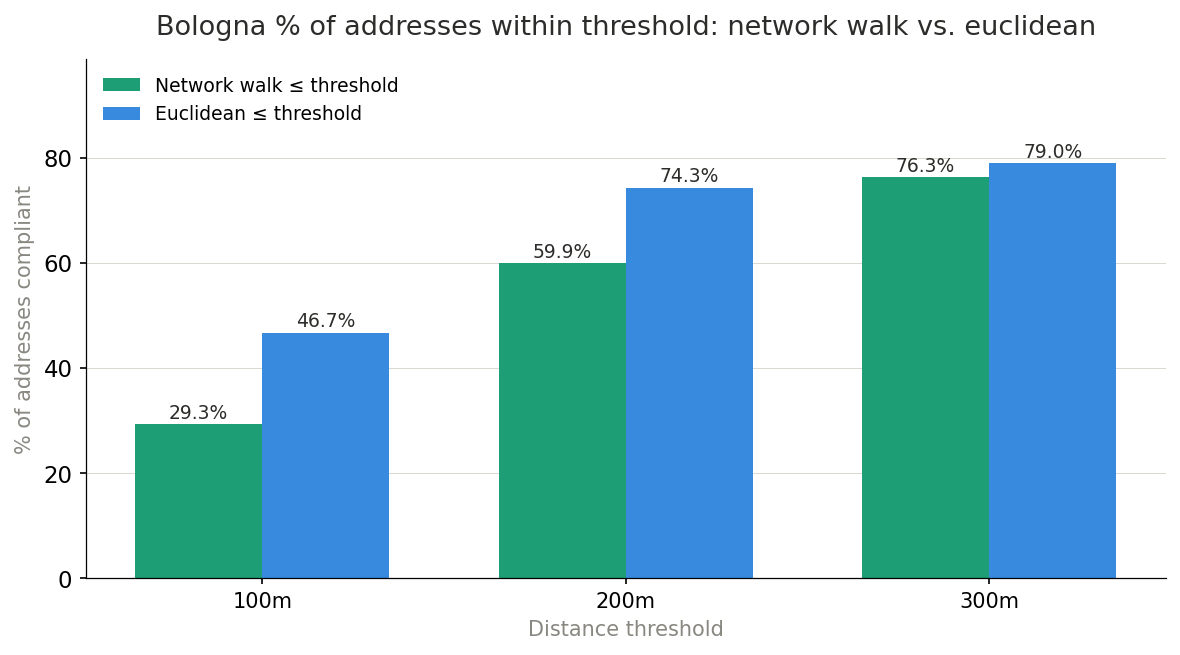

In [130]:

fig, ax = plt.subplots(figsize=(8, 4.5))

# Grouped bars, no secondary axis
b1 = ax.bar(x - w/2, walk_pct_real,   width=w, color=TEAL, label="Network walk ≤ threshold",  zorder=2, linewidth=0)
b2 = ax.bar(x + w/2, euclid_pct_real, width=w, color=BLUE, label="Euclidean ≤ threshold", zorder=2, linewidth=0)

# Value labels above bars
for bars in (b1, b2):
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.4,
            f"{bar.get_height():.1f}%", ha="center", va="bottom", fontsize=9, color=TEXT)



ax.set_xticks(x)
ax.set_xticklabels([f"{t}m" for t in dist_thresholds], fontsize=10)
ax.set_ylabel("% of addresses compliant", fontsize=10, color=SGRAY)
ax.set_xlabel("Distance threshold", fontsize=10, color=SGRAY)
ax.set_title(
    f"{CITY.title()} % of addresses within threshold: network walk vs. euclidean",
    fontsize=13, fontweight="500", pad=12, color=TEXT
)
ax.set_ylim(0, max(euclid_pct_real) * 1.25)
ax.grid(axis="y", linewidth=0.4, color=LGRAY, zorder=0)

# clean single legend
ax.legend(handles=[b1, b2], fontsize=9, frameon=False,
    loc="upper left")

plt.tight_layout()
plt.savefig("fig/fig05_euclid_vs_walk.png", bbox_inches="tight", dpi=150)
plt.show()

In [148]:
# 1. basic sanity — euclid must always be <= walk
impossible = matched[matched["euclid_dist_m"] > matched["walk_dist_m"]]
print(f"impossible rows (euclid > walk): {len(impossible)}")  # must be 0

# 2. distribution comparison
print("\nwalk_dist_m:")
print(matched["walk_dist_m"].describe().round(1))
print("\neuclid_dist_m:")
print(matched["euclid_dist_m"].describe().round(1))
# mean euclid should be consistently lower than mean walk

# 3. the gap at 300m broken down manually
walk_compliant   = (matched["walk_dist_m"]   <= 300).sum()
euclid_compliant = (matched["euclid_dist_m"] <= 300).sum()
overcounted      = ((matched["euclid_dist_m"] <= 300) & (matched["walk_dist_m"] > 300)).sum()

print(f"walk  ≤ 300m: {walk_compliant:,}  ({walk_compliant/total*100:.1f}%)")
print(f"euclid ≤ 300m: {euclid_compliant:,}  ({euclid_compliant/total*100:.1f}%)")
print(f"overcounted:   {overcounted:,}  ({overcounted/total*100:.1f}%)")
# difference and overcounted should be identical numbers

impossible rows (euclid > walk): 7754

walk_dist_m:
count    61360.0
mean       141.5
std        106.2
min          0.0
25%         71.3
50%        130.5
75%        197.5
max       3183.6
Name: walk_dist_m, dtype: float64

euclid_dist_m:
count    61360.0
mean        93.2
std         60.4
min          0.0
25%         44.1
50%         84.3
75%        132.3
max        481.5
Name: euclid_dist_m, dtype: float64
walk  ≤ 300m: 59,212  (76.3%)
euclid ≤ 300m: 61,311  (79.0%)
overcounted:   2,107  (2.7%)


## fig06. access gap map (300m compliance)

- Each dot = one civic address, plotted at its lon/lat.
- Teal  = within 300m walk of a park
- Coral = outside 300m (the access gap)


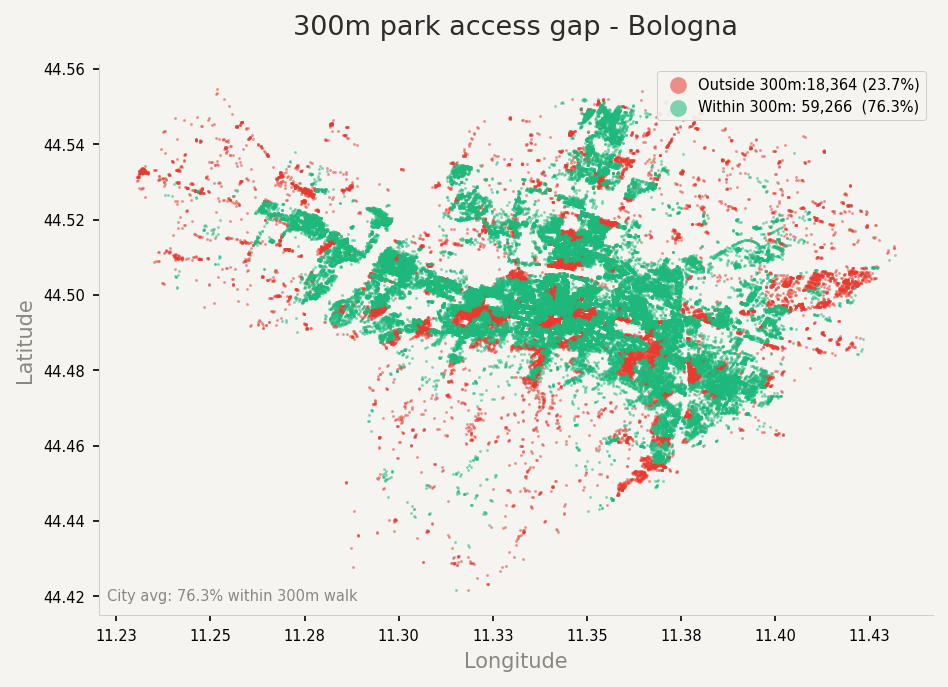

In [133]:
# Brighter colours for dot map
DOT_OUT = "#E83A2F"   # vivid red for outside (the problem)
DOT_IN  = "#1DB87A"   # vivid green for inside (the good)

inside  = results[results["within_300m"]]
outside = results[~results["within_300m"]]

lon_range = results["longitude"].max() - results["longitude"].min()
lat_range = results["latitude"].max()  - results["latitude"].min()
lat_mid   = results["latitude"].mean()
aspect    = lon_range / (lat_range * np.cos(np.radians(lat_mid)))
fig_w, fig_h = 10, 10 / aspect

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
fig.patch.set_facecolor("#F5F4F0")
ax.set_facecolor("#F5F4F0")

# Draw outside first (red), inside on top (green)
ax.scatter(outside["longitude"], outside["latitude"],
    s=1.8, color=DOT_OUT, alpha=0.55, linewidths=0,
    label=f"Outside 300m:{len(outside):,} ({len(outside)/total*100:.1f}%)",
    rasterized=True, zorder=2)
ax.scatter(inside["longitude"], inside["latitude"],
    s=1.8, color=DOT_IN,  alpha=0.55, linewidths=0,
    label=f"Within 300m: {len(inside):,}  ({len(inside)/total*100:.1f}%)",
    rasterized=True, zorder=3)

ax.set_aspect("equal")
ax.set_xlabel("Longitude", fontsize=10, color=SGRAY)
ax.set_ylabel("Latitude",  fontsize=10, color=SGRAY)
ax.set_title("300m park access gap - Bologna",
    fontsize=13, fontweight="500", pad=14, color=TEXT)
ax.xaxis.set_major_formatter(plt.FormatStrFormatter("%.2f"))
ax.yaxis.set_major_formatter(plt.FormatStrFormatter("%.2f"))
ax.tick_params(labelsize=7)
for spine in ax.spines.values():
    spine.set_edgecolor(LGRAY)
    spine.set_linewidth(0.5)

# Legend upper right, slightly inset
legend = ax.legend(
    fontsize=7, frameon=True, framealpha=0.92, loc="upper right",
    markerscale=6, handletextpad=0.4,
)
legend.get_frame().set_linewidth(0.5)
legend.get_frame().set_facecolor("#F5F4F0")

ax.text(0.01, 0.02, f"City avg: {avg:.1f}% within 300m walk",
    transform=ax.transAxes, fontsize=7, color=SGRAY, ha="left", va="bottom")

plt.tight_layout()
plt.savefig("fig/fig06_access_gap_map.png", dpi=200, bbox_inches="tight")
plt.show()

In [134]:
area_statistiche = gpd.read_file('data/300m/bologna_aree_statistiche.geojson')

## fig07. choropleth by sub-city zones
Requires a GeoJSON with sub-city statistical/administrative areas.
Set `ZONES_FILE` and `ZONES_ID_COL` below — leave `ZONES_FILE = None` to skip.

In [ ]:
ZONES_FILE   = src.get("zones")                     # add "zones" key to config to use
ZONES_ID_COL = "area_statistica"                    # adjust per city if needed


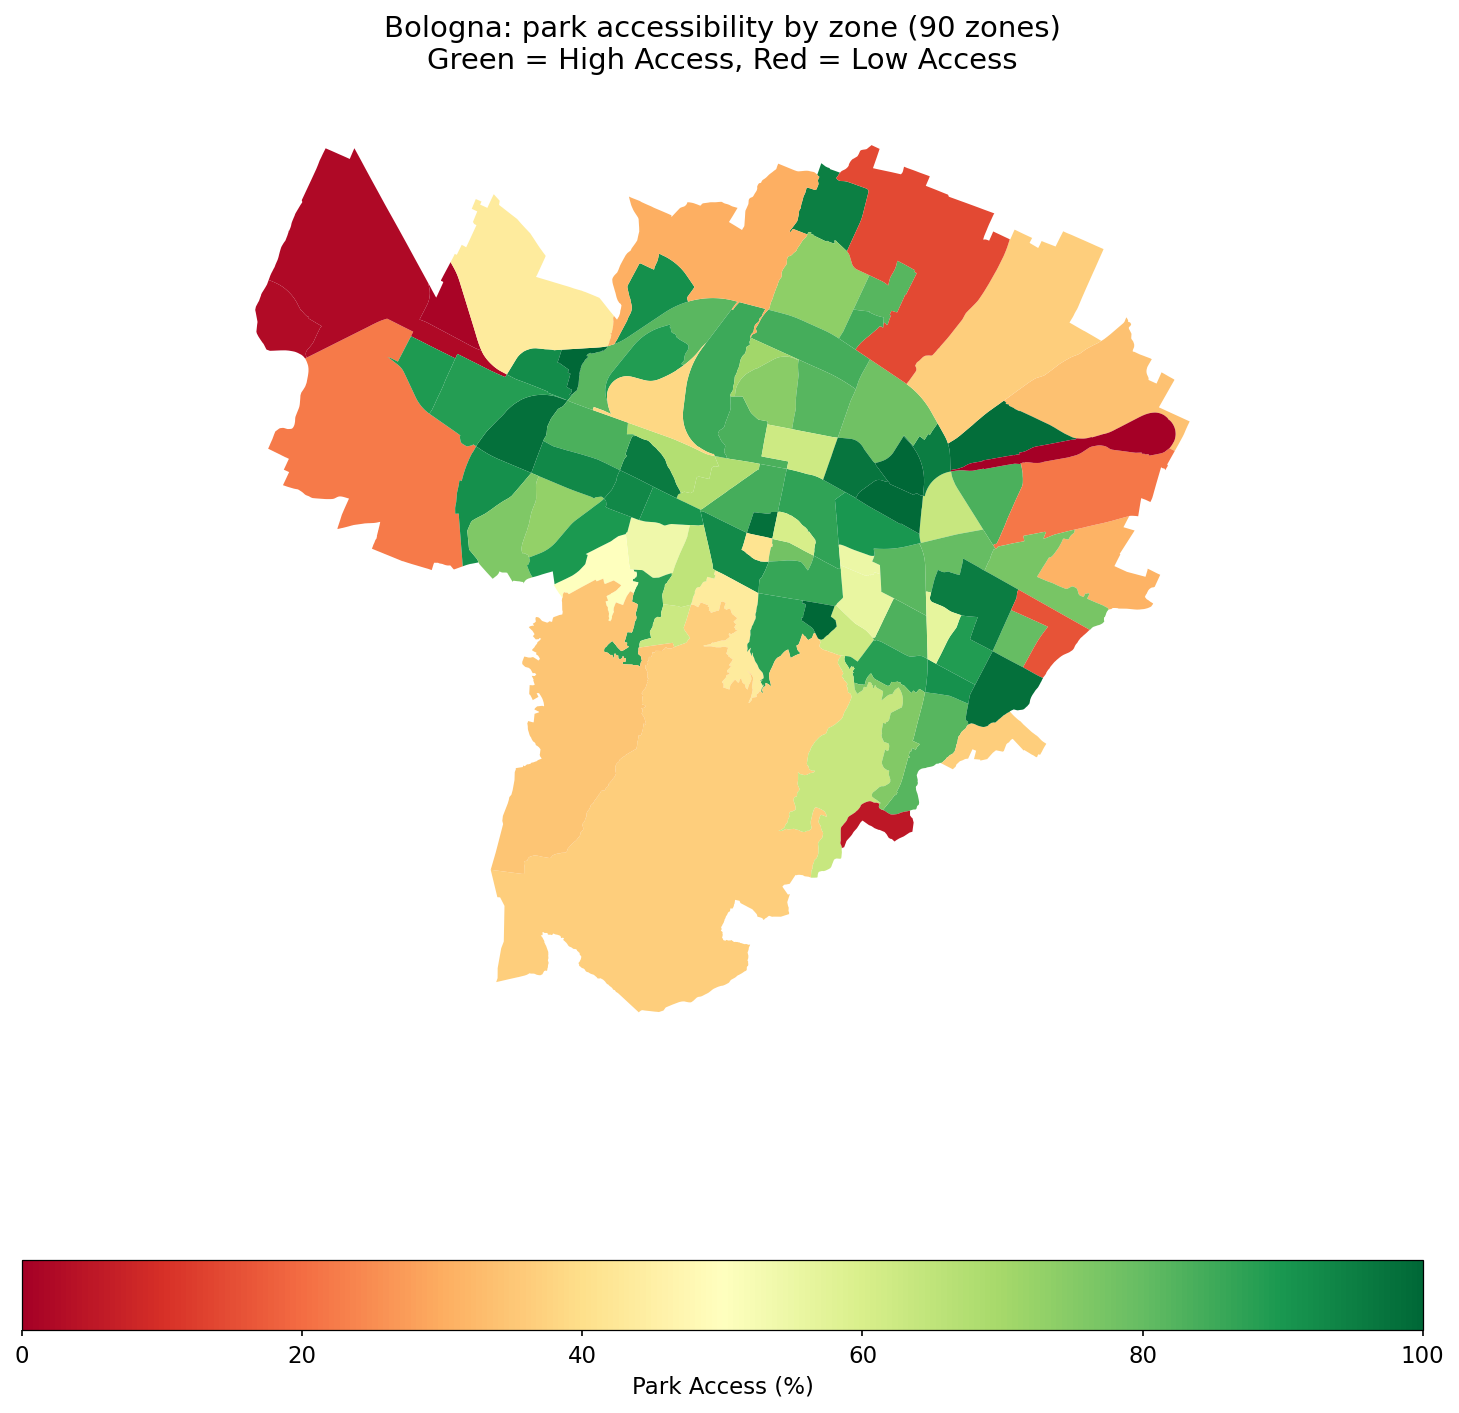

In [141]:


zones = area_statistiche

results["within_300m"] = results["within_300m"].fillna(False).astype(bool)
results_gdf = gpd.GeoDataFrame(
    results,
    geometry=gpd.points_from_xy(results["longitude"], results["latitude"]),
    crs=CRS_WGS,
)

joined = gpd.sjoin(
    results_gdf,
    zones[[ZONES_ID_COL, "geometry"]],
    how="left",
    predicate="within",
)
stats = (
    joined.groupby(ZONES_ID_COL)
    .agg(total_points=("within_300m", "count"),
       access_points=("within_300m", "sum"))
    .reset_index()
    .assign(access_pct=lambda df: df.access_points / df.total_points * 100)
)

gdf_plot = zones.merge(stats[[ZONES_ID_COL, "access_pct"]], on=ZONES_ID_COL, how="left")
gdf_plot["access_pct"] = gdf_plot["access_pct"].fillna(0)

fig, ax = plt.subplots(figsize=(12, 10))
gdf_plot.plot(
    column="access_pct", cmap="RdYlGn", linewidth=0.5,
    ax=ax, legend=True, vmin=0, vmax=100,
    legend_kwds={"label": "Park Access (%)", "shrink": 0.8, "orientation": "horizontal"},
)
ax.set_title(
f"{CITY.title()}: park accessibility by zone ({len(zones)} zones)\n"
"Green = High Access, Red = Low Access",
fontsize=14, pad=16,
)
ax.axis("off")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig07_park_access_choropleth.png", dpi=300)
plt.show()

In [ ]:
#per statistical area acess
zones = area_statistiche

results["within_300m"] = results["within_300m"].fillna(False).astype(bool)
results_gdf = gpd.GeoDataFrame(
    results,
    geometry=gpd.points_from_xy(results["longitude"], results["latitude"]),
    crs=CRS_WGS,
    )

joined = gpd.sjoin(
    results_gdf,
    zones[[ZONES_ID_COL, "geometry"]],
    how="left",
    predicate="within",
    )
stats = (
    joined.groupby(ZONES_ID_COL)
    .agg(total_points=("within_300m", "count"),
            access_points=("within_300m", "sum"))
    .reset_index()
    .assign(access_pct=lambda df: df.access_points / df.total_points * 100)
)

zone_table = (
    stats
    .rename(columns={
        ZONES_ID_COL:    "zone",
        "total_points":  "total_addresses",
        "access_points": "within_300m",
        "access_pct":    "pct_within_300m",
    })
    .sort_values("pct_within_300m", ascending=False)
    .round({"pct_within_300m": 1})
    .reset_index(drop=True)
)

print(f"\n{CITY.title()}: park access by statistical area ({len(zone_table)} zones)")
print(zone_table.to_string(index=False))

print(f"\nWORST 5:")
print(zone_table.tail(5).to_string(index=False))

print(f"\nBEST 5:")
print(zone_table.head(5).to_string(index=False))

# optional: save as csv
zone_table.to_csv(f"{FIG_DIR}/{CITY}_access_by_zone.csv", index=False)




Bologna: park access by statistical area (90 zones)
                              zone  total_addresses  within_300m  pct_within_300m
                        LUNGO RENO                4            4            100.0
               GIARDINI MARGHERITA               21           21            100.0
                         MICHELINO              763          762             99.9
                         VIA MONDO             1200         1193             99.4
                          PILASTRO              477          471             98.7
                         MARCONI-1             1406         1381             98.2
                TRIUMVIRATO-PIETRA             1199         1177             98.2
                          VIA ARNO              758          744             98.2
                    VIA DEL LAVORO             1248         1211             97.0
PRATI DI CAPRARA-OSPEDALE MAGGIORE               74           71             95.9
                           FOSSOLO           

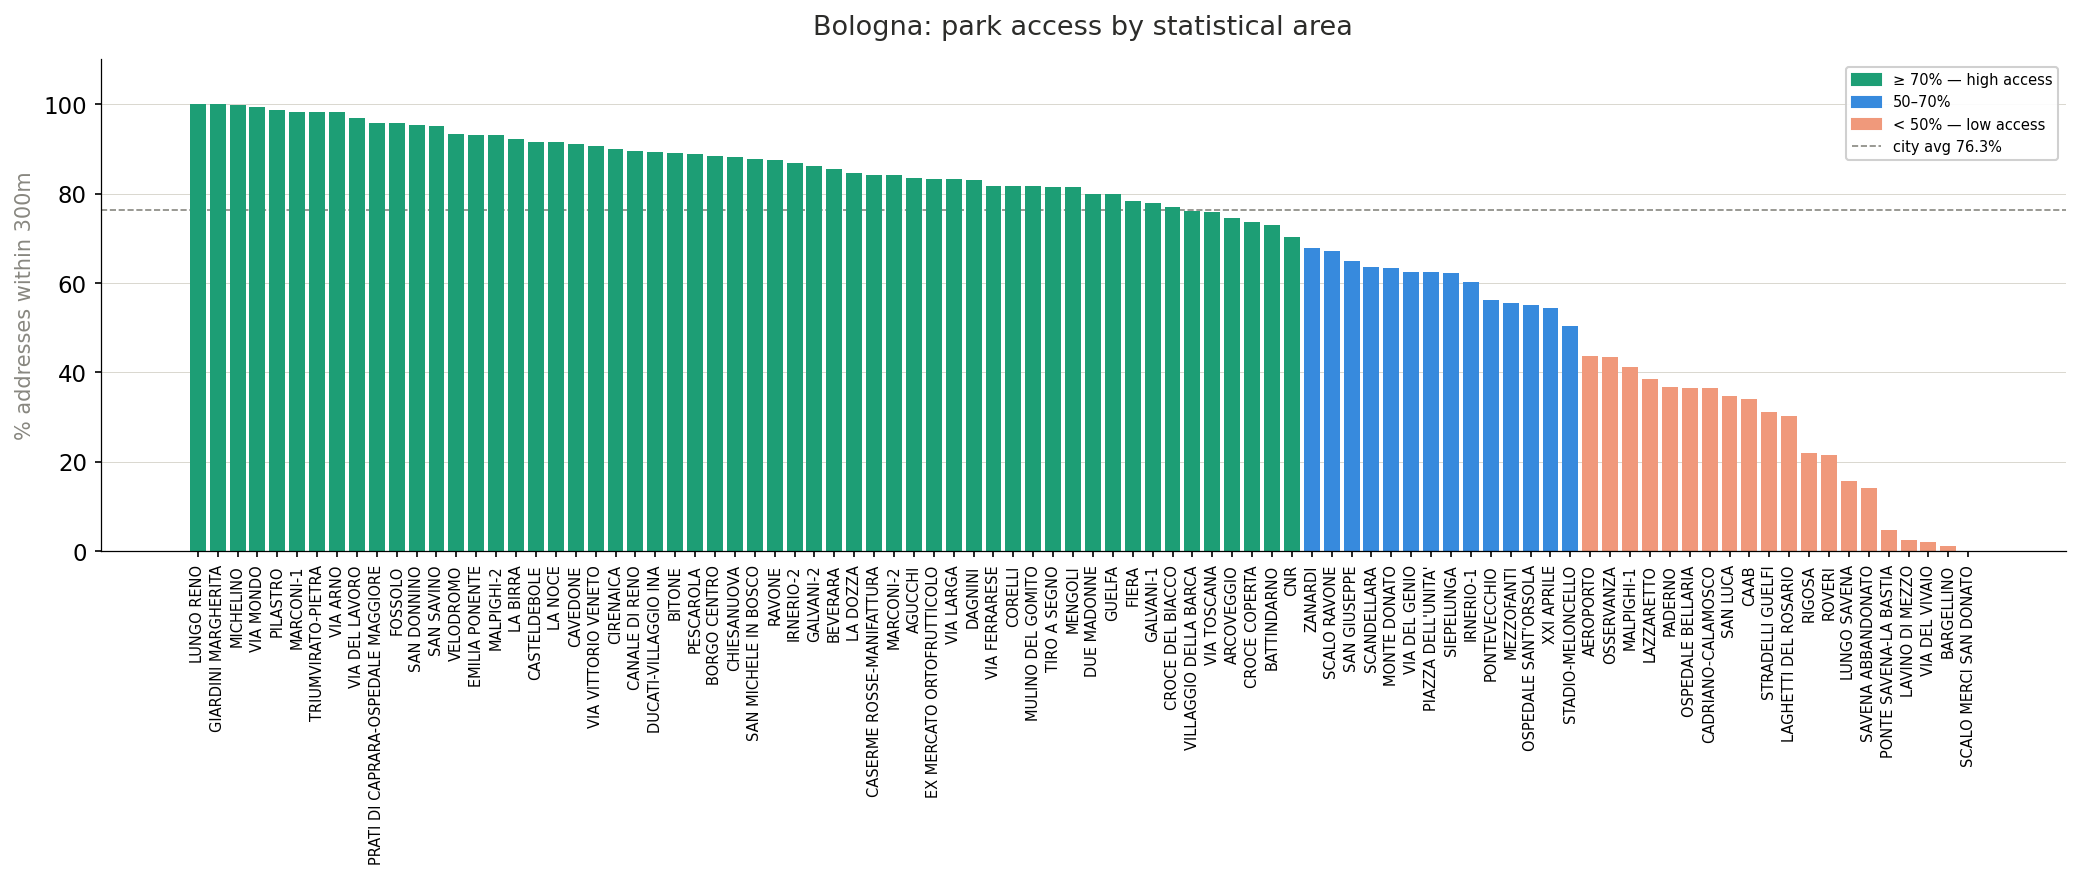

In [155]:
fig, ax = plt.subplots(figsize=(14, 6))

colors = [TEAL if p >= 70 else BLUE if p >= 50 else CORAL for p in zone_table["pct_within_300m"]]
legend_els = [
    mpatches.Patch(color=TEAL,  label="≥ 70% — high access"),
    mpatches.Patch(color=BLUE,  label="50–70%"),
    mpatches.Patch(color=CORAL, label="< 50% — low access"),
]


city_avg = results["within_300m"].mean() * 100  

ax.axhline(city_avg, color=SGRAY, linewidth=0.8, linestyle="--", zorder=1)

ax.legend(
    handles=legend_els + [plt.Line2D([0], [0], color=SGRAY, linewidth=0.8,
                                      linestyle="--", label=f"city avg {city_avg:.1f}%")],
    fontsize=7, frameon=True, framealpha=0.92, loc="upper right",
)

ax.bar(range(len(zone_table)), zone_table["pct_within_300m"], color=colors, zorder=2)


ax.set_xticks(range(len(zone_table)))
ax.set_xticklabels(zone_table["zone"], rotation=90, fontsize=7)
ax.set_ylabel("% addresses within 300m", fontsize=10, color=SGRAY)
ax.set_ylim(0, 110)
ax.set_title(f"{CITY.title()}: park access by statistical area",
             fontsize=13, fontweight="500", color=TEXT, pad=12, )
ax.grid(axis="y", linewidth=0.4, color=LGRAY, zorder=0)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig08_access_by_zone_bar.png", dpi=150)
plt.show()